## Assignment no 9

## DATA PREPROCESSING AND FEATURE ENGINEERING IN MACHINE LEARNING


Setup & Imports

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("adult_with_headers.csv")

# Numeric vs categorical
num_cols = ["age", "fnlwgt", "education_num",
            "capital_gain", "capital_loss", "hours_per_week"]
cat_cols = ["workclass", "education", "marital_status", "occupation",
            "relationship", "race", "sex", "native_country"]
target = "income"

print("Shape:", df.shape)
print("\nNumeric cols:", num_cols)
print("Categorical cols:", cat_cols)

Shape: (32561, 15)

Numeric cols: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical cols: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


Task 1 — Handle Missing Values

In [51]:
# The file encodes missing values as the string "?"
print("Rows with any '?':", (df == "?").any(axis=1).sum())
print("\nMissing count per column (where > 0):")
for c in df.columns:
    n = (df[c] == "?").sum()
    if n > 0:
        print(f"  {c:<20s}: {n:>4d}   ({100 * n / len(df):5.2f}%)")

Rows with any '?': 0

Missing count per column (where > 0):


In [52]:
df_clean = df.copy()
df_clean = df_clean.replace("?", np.nan)

# Target must never be missing
df_clean = df_clean.dropna(subset=[target])

# Encode target to 0/1
df_clean[target] = (df_clean[target] == ">50K").astype(int)

print("NaN after conversion:\n", df_clean.isna().sum())

NaN after conversion:
 age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64


In [53]:
X = df_clean.drop(target, axis=1)
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train positive rate:", y_train.mean().round(3))
print("Test  positive rate:", y_test.mean().round(3))

Train: (26048, 14) | Test: (6513, 14)
Train positive rate: 0.0
Test  positive rate: 0.0


In [54]:
cat_pipe_mode = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

X_train_A = cat_pipe_mode.fit_transform(X_train[cat_cols])
X_test_A  = cat_pipe_mode.transform(X_test[cat_cols])
print("Strategy A output shape:", X_train_A.shape)

Strategy A output shape: (26048, 102)


In [55]:
# Fill missing with the literal string "Unknown"
cat_train_B = X_train[cat_cols].fillna("Unknown")
cat_test_B  = X_test[cat_cols].fillna("Unknown")

onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_train_B = onehot.fit_transform(cat_train_B)
X_test_B  = onehot.transform(cat_test_B)
print("Strategy B output shape:", X_train_B.shape)

Strategy B output shape: (26048, 102)


In [56]:
# Example for numeric columns — including a hypothetical missing rate
# (in this dataset numerics aren't missing, but this is the pattern)
num_pipe_knn = Pipeline([
    ("imputer", KNNImputer(n_neighbors=5)),
    ("scaler",  StandardScaler()),
])
X_train_num_C = num_pipe_knn.fit_transform(X_train[num_cols])
print("Strategy C numeric shape:", X_train_num_C.shape)

Strategy C numeric shape: (26048, 6)


Production-ready imputation pipeline

In [57]:
from sklearn.compose import ColumnTransformer

num_imputer_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # safety net; no-op here
])

cat_imputer_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor_impute_only = ColumnTransformer([
    ("num", num_imputer_pipe, num_cols),
    ("cat", cat_imputer_pipe, cat_cols),
])

# Fit on train, apply to test — no leakage
X_train_imp = preprocessor_impute_only.fit_transform(X_train)
X_test_imp  = preprocessor_impute_only.transform(X_test)
print("Imputed train shape:", X_train_imp.shape)
print("Any NaN in output:", np.isnan(X_train_imp).any())

Imputed train shape: (26048, 108)
Any NaN in output: False


Task 2 — Apply Feature Scaling

Inspect raw scale differences

In [58]:
print(X_train[num_cols].describe().T[["mean", "std", "min", "max"]].round(2))
print("\nSkewness:")
print(X_train[num_cols].skew().round(2))

                     mean        std      min        max
age                 38.59      13.66     17.0       90.0
fnlwgt          189429.28  105239.77  12285.0  1484705.0
education_num       10.07       2.57      1.0       16.0
capital_gain      1059.37    7292.06      0.0    99999.0
capital_loss        85.70     399.78      0.0     4356.0
hours_per_week      40.40      12.34      1.0       99.0

Skewness:
age                0.56
fnlwgt             1.45
education_num     -0.32
capital_gain      12.11
capital_loss       4.65
hours_per_week     0.24
dtype: float64


2a. Standard Scaling (z-score)

In [59]:
from sklearn.preprocessing import StandardScaler

scaler_std = StandardScaler()
X_num_std_train = scaler_std.fit_transform(X_train[num_cols])
X_num_std_test  = scaler_std.transform(X_test[num_cols])

# Check the transformation
std_check = pd.DataFrame(
    X_num_std_train, columns=num_cols
).describe().T[["mean", "std", "min", "max"]].round(3)
print("After StandardScaler:")
print(std_check)

After StandardScaler:
                mean  std    min     max
age              0.0  1.0 -1.581   3.764
fnlwgt           0.0  1.0 -1.683  12.308
education_num    0.0  1.0 -3.523   2.304
capital_gain    -0.0  1.0 -0.145  13.568
capital_loss    -0.0  1.0 -0.214  10.682
hours_per_week  -0.0  1.0 -3.192   4.747


2b. Min-Max Scaling

In [60]:
from sklearn.preprocessing import MinMaxScaler

scaler_mm = MinMaxScaler()
X_num_mm_train = scaler_mm.fit_transform(X_train[num_cols])
X_num_mm_test  = scaler_mm.transform(X_test[num_cols])

mm_check = pd.DataFrame(
    X_num_mm_train, columns=num_cols
).describe().T[["mean", "std", "min", "max"]].round(3)
print("After MinMaxScaler:")
print(mm_check)

After MinMaxScaler:
                 mean    std  min  max
age             0.296  0.187  0.0  1.0
fnlwgt          0.120  0.071  0.0  1.0
education_num   0.605  0.172  0.0  1.0
capital_gain    0.011  0.073  0.0  1.0
capital_loss    0.020  0.092  0.0  1.0
hours_per_week  0.402  0.126  0.0  1.0


2c. Visual comparison of the three approaches

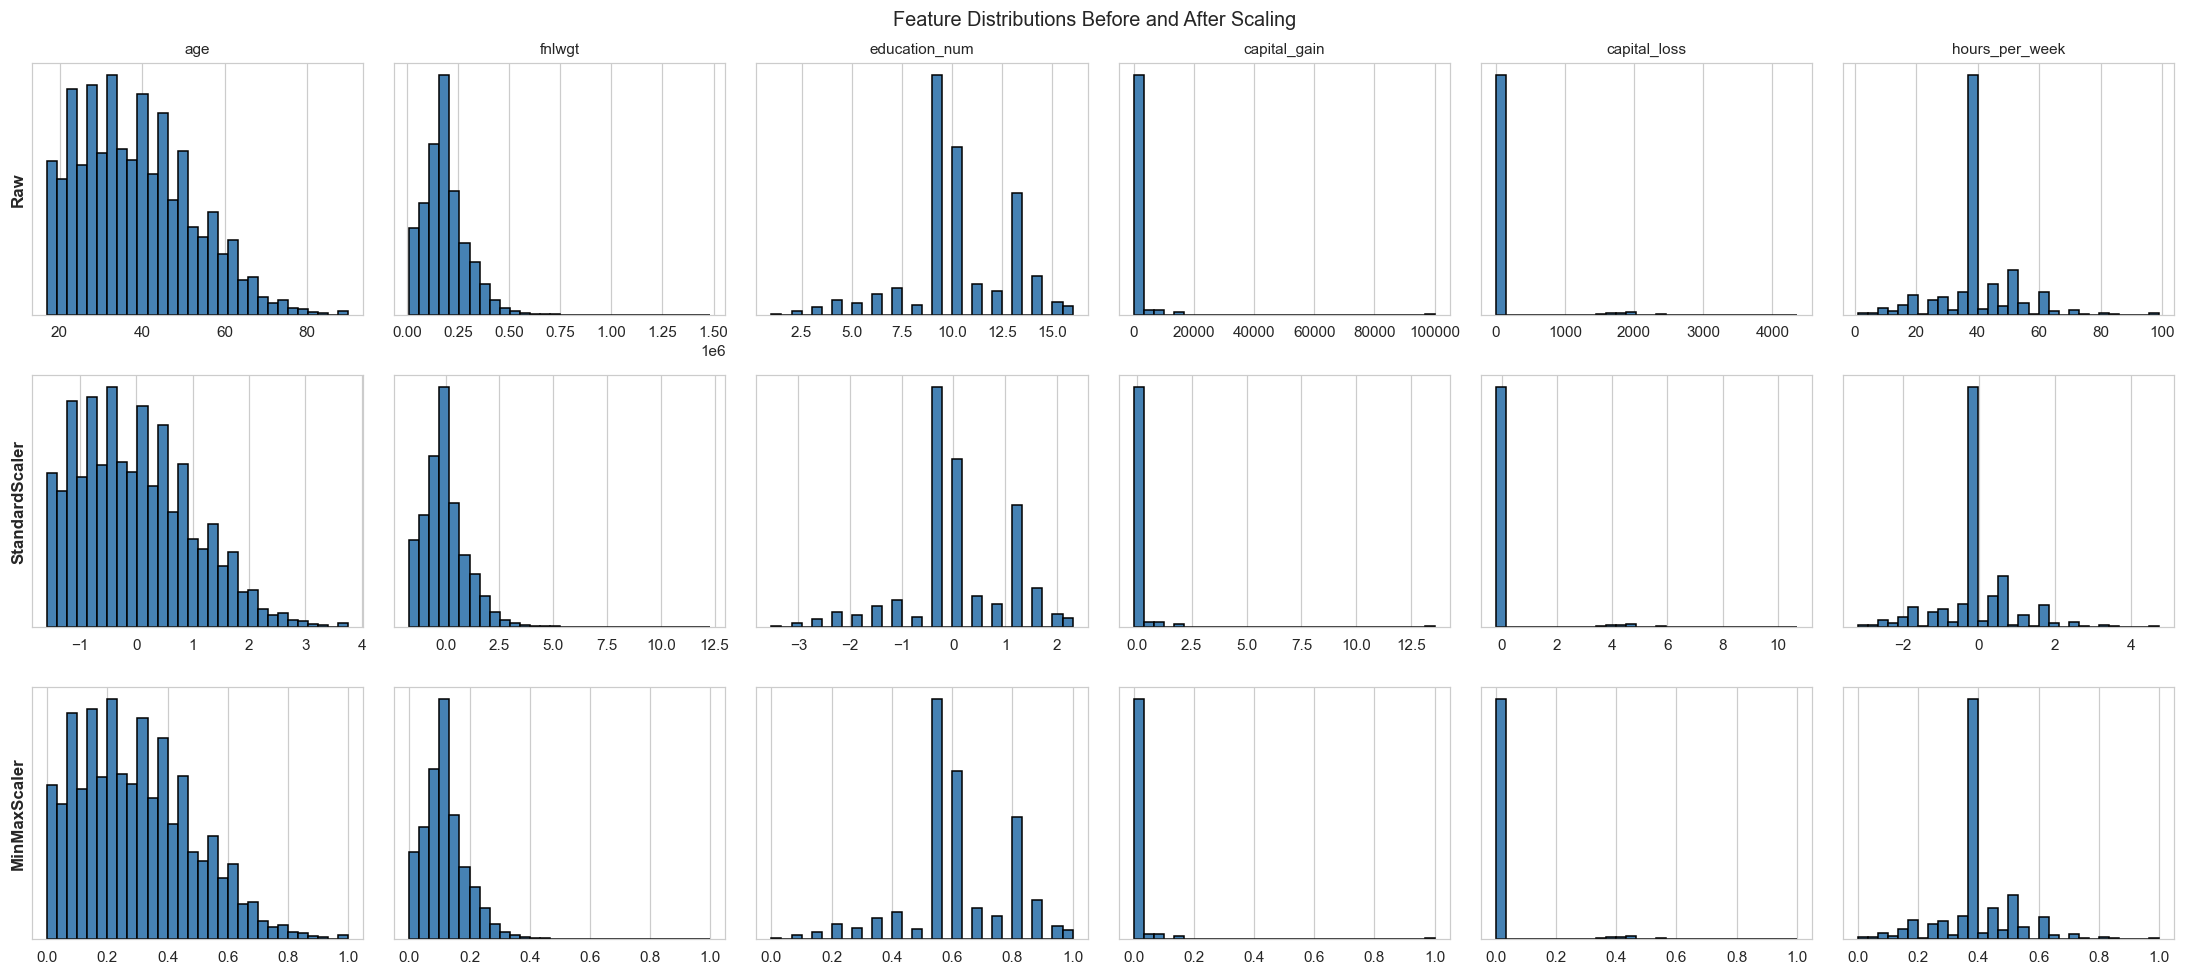

In [61]:
fig, axes = plt.subplots(3, 6, figsize=(20, 9))
row_titles = ["Raw", "StandardScaler", "MinMaxScaler"]
data_by_row = [
    X_train[num_cols].values,
    X_num_std_train,
    X_num_mm_train,
]

for r, (title, data) in enumerate(zip(row_titles, data_by_row)):
    for c, col in enumerate(num_cols):
        ax = axes[r, c]
        ax.hist(data[:, c], bins=30, color="steelblue", edgecolor="black")
        if r == 0:
            ax.set_title(col, fontsize=10)
        ax.set_yticks([])
    axes[r, 0].set_ylabel(title, fontsize=11, fontweight="bold")

plt.suptitle("Feature Distributions Before and After Scaling", fontsize=13)
plt.tight_layout(); plt.show()

2d. Compare downstream model performance

In [62]:
import numpy as np, pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# ---- load & clean ----
df = pd.read_csv("adult_with_headers.csv", na_values="?")
df = df.apply(lambda s: s.str.strip() if s.dtype == object else s)

y = df["income"].map({">50K": 1, "<=50K": 0})
X = df.drop(columns=["income", "fnlwgt", "education"])   # fnlwgt = weight, education = ordinal dup

num_cols = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
cat_cols = ["workclass", "marital_status", "occupation", "relationship",
            "race", "sex", "native_country"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# ---- your build_pipeline ----
def build_pipeline(scaler):
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  scaler),
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    prep = ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols),
    ])
    return Pipeline([
        ("prep", prep),
        ("clf", LogisticRegression(max_iter=2000, random_state=42)),
    ])

results = {}
for name, scaler in [
    ("None",     "passthrough"),
    ("Standard", StandardScaler()),
    ("MinMax",   MinMaxScaler()),
    ("Robust",   RobustScaler()),
]:
    p = build_pipeline(scaler)
    p.fit(X_train, y_train)
    auc = roc_auc_score(y_test, p.predict_proba(X_test)[:, 1])
    results[name] = auc

print(pd.Series(results).round(4))

c:\Users\yashr\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


None        0.9102
Standard    0.9097
MinMax      0.9074
Robust      0.9100
dtype: float64


c:\Users\yashr\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


2. Encoding Techniques


In [63]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

# treat missing as its own category ("Unknown") so the flag isn't erased by mode-imputation
df[cat_cols] = df[cat_cols].fillna("Unknown")
card = df[cat_cols].nunique()

ohe_cols = card[card < 5].index.tolist()     # ['sex']
le_cols  = card[card > 5].index.tolist()     # the >5 columns
# race (==5) is left out by the literal rule -> assign deliberately (see note)

In [64]:
ohe_cols = card[card <= 5].index.tolist()    # ['sex', 'race']   <- if you choose "<=5"
le_cols  = card[card >  5].index.tolist()    # everything else

In [65]:
# --- One-Hot ---
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)  # sparse=False on sklearn <1.2
ohe_df = pd.DataFrame(
    ohe.fit_transform(df[ohe_cols]),
    columns=ohe.get_feature_names_out(ohe_cols),
    index=df.index,
)

# --- Label ---
le_df, encoders = df[le_cols].copy(), {}
for c in le_cols:
    le = LabelEncoder().fit(df[c])
    le_df[c] = le.transform(df[c])
    encoders[c] = le

print(ohe.get_feature_names_out(ohe_cols))   # ['sex_Female','sex_Male', 'race_...']
for c, le in encoders.items():
    print(c, dict(zip(le.classes_[:4], range(4))))   # verify integer mapping

['race_Amer-Indian-Eskimo' 'race_Asian-Pac-Islander' 'race_Black'
 'race_Other' 'race_White' 'sex_Female' 'sex_Male']
workclass {'?': 0, 'Federal-gov': 1, 'Local-gov': 2, 'Never-worked': 3}
marital_status {'Divorced': 0, 'Married-AF-spouse': 1, 'Married-civ-spouse': 2, 'Married-spouse-absent': 3}
occupation {'?': 0, 'Adm-clerical': 1, 'Armed-Forces': 2, 'Craft-repair': 3}
relationship {'Husband': 0, 'Not-in-family': 1, 'Other-relative': 2, 'Own-child': 3}
native_country {'?': 0, 'Cambodia': 1, 'Canada': 2, 'China': 3}


In [66]:
y = df["income"].map({">50K": 1, "<=50K": 0})
X = pd.concat([df[num_cols], ohe_df, le_df], axis=1)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          stratify=y, random_state=42)
# for production: fit OneHotEncoder/LabelEncoder on X_tr only, then .transform(X_te)
# and map unseen test levels -> len(classes_) so LabelEncoder never throws

3. Feature Engineering:

In [67]:
num_cols  = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]

Step 1 — Establish a baseline before adding anything

In [68]:
from sklearn.feature_selection import mutual_info_classif

mi_before = pd.Series(
    mutual_info_classif(X_tr, y_tr, discrete_features="auto", random_state=42),
    index=X_tr.columns,
).sort_values(ascending=False)
print(mi_before.head(15))

relationship               0.112772
marital_status             0.108926
capital_gain               0.082695
age                        0.067055
occupation                 0.067048
education_num              0.063913
hours_per_week             0.041278
capital_loss               0.035011
sex_Male                   0.031255
sex_Female                 0.026836
workclass                  0.015765
native_country             0.007367
race_White                 0.005062
race_Black                 0.001188
race_Asian-Pac-Islander    0.000000
dtype: float64


Step 2 — Three new features

In [69]:
def engineer(df):
    df = df.copy()
    df["net_capital"]   = df["capital_gain"] - df["capital_loss"]
    df["has_capital"]   = ((df["capital_gain"] > 0) | (df["capital_loss"] > 0)).astype(int)
    df["human_capital"] = df["education_num"] * df["hours_per_week"]
    return df

X_tr, X_te = engineer(X_tr), engineer(X_te)



Step 3 — Log transformation of a skewed feature

3a. Measure skew first


In [70]:
from scipy.stats import skew

for c in ["age", "capital_gain", "capital_loss", "hours_per_week"]:
    print(f"{c:16s} skew = {skew(X_tr[c]):7.2f}")

age              skew =    0.56
capital_gain     skew =   12.08
capital_loss     skew =    4.59
hours_per_week   skew =    0.25


3b. Apply it

In [71]:
X_tr["capital_gain_log"] = np.log1p(X_tr["capital_gain"])
X_te["capital_gain_log"] = np.log1p(X_te["capital_gain"])
X_tr["capital_loss_log"] = np.log1p(X_tr["capital_loss"])
X_te["capital_loss_log"] = np.log1p(X_te["capital_loss"])

Validate that the engineering actually helped

In [72]:
mi_after = pd.Series(
    mutual_info_classif(X_tr, y_tr, discrete_features="auto", random_state=42),
    index=X_tr.columns,
).sort_values(ascending=False)

new_feats = ["net_capital", "has_capital", "human_capital",
             "capital_gain_log", "capital_loss_log"]

comparison = pd.DataFrame({
    "mi_before": mi_before.reindex(new_feats),
    "mi_after":  mi_after.reindex(new_feats),
})
print(comparison.round(4))
print("\nTop 15 after:\n", mi_after.head(15))

                  mi_before  mi_after
net_capital             NaN    0.1208
has_capital             NaN    0.0349
human_capital           NaN    0.0802
capital_gain_log        NaN    0.0852
capital_loss_log        NaN    0.0386

Top 15 after:
 net_capital         0.120752
relationship        0.114828
marital_status      0.110435
capital_gain_log    0.085159
human_capital       0.080232
capital_gain        0.079675
age                 0.068039
education_num       0.064210
occupation          0.063180
hours_per_week      0.040660
capital_loss_log    0.038599
capital_loss        0.037300
has_capital         0.034893
sex_Male            0.033829
sex_Female          0.028014
dtype: float64


In [73]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

base   = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
base.fit(X_tr[num_cols], y_tr)
print("AUC without engineering:", roc_auc_score(y_te, base.predict_proba(X_te[num_cols])[:, 1]))

eng_cols = num_cols + ["net_capital", "has_capital", "human_capital",
                       "capital_gain_log", "capital_loss_log"]
eng = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
eng.fit(X_tr[eng_cols], y_tr)
print("AUC with engineering:   ", roc_auc_score(y_te, eng.predict_proba(X_te[eng_cols])[:, 1]))

AUC without engineering: 0.8371940839025195
AUC with engineering:    0.8435378448649429
